# Supplementary Figure S9b. Glial recipients of excitatory- and inhibitory-neuron *cis* signals

Among *cis*-*trans* loci whose initiating (*cis*) and recipient (*trans*, eGene union eProgram) cell-type sets are both non-empty and disjoint and whose *cis* set contains the target neuron (Exc, left; Inh, right), the statistic for each glial type *g* is (# loci with *g* in the recipient set) / (# loci with the other neuron type in the recipient set). Enrichment = observed statistic / mean of the statistic over 1,000 independent shuffles of cell-type labels within the *cis* and within the *trans* side across all 164,160 CoS (CoS slots and bulk support fixed; seed 42). Error bars are shuffle reference bounds, observed / 97.5% and observed / 2.5% quantiles of the null statistic; they are not a bootstrap confidence interval of the estimate. One-sided empirical P = (1 + # null >= observed) / 1,001, BH-adjusted across the eight comparisons; *** FDR < 0.001 (0.000999 is the smallest attainable P).

Input: `data/Figure_S9b_neuron_glia_enrichment.rds`

In [1]:
library(ggplot2)
res <- readRDS("data/Figure_S9b_neuron_glia_enrichment.rds")
res

cis_neuron,trans_glia,comparator,n_eligible,target_count,comparator_count,observed_ratio,null_mean_ratio,enrichment,bound_low,bound_high,n_exceed,p_perm,fdr,sig
<fct>,<fct>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
Excitatory neuron,Microglia,Inh,761,283,177,1.598870,1.066543,1.499114,1.275501,1.754138,0,0.000999001,0.000999001,***
Excitatory neuron,Astrocyte,Inh,761,298,177,1.683616,1.165419,1.444644,1.238508,1.690467,0,0.000999001,0.000999001,***
Excitatory neuron,Oligodendrocyte,Inh,761,313,177,1.768362,1.161007,1.523128,1.316549,1.768362,0,0.000999001,0.000999001,***
Excitatory neuron,OPC,Inh,761,349,177,1.971751,1.224884,1.609745,1.395164,1.883645,0,0.000999001,0.000999001,***
Inhibitory neuron,Microglia,Exc,361,155,28,5.535714,1.638707,3.378098,2.647439,4.328869,0,0.000999001,0.000999001,***
Inhibitory neuron,Astrocyte,Exc,361,148,28,5.285714,1.794272,2.945882,2.367903,3.786796,0,0.000999001,0.000999001,***
Inhibitory neuron,Oligodendrocyte,Exc,361,138,28,4.928571,1.785060,2.761012,2.169780,3.503016,0,0.000999001,0.000999001,***
Inhibitory neuron,OPC,Exc,361,169,28,6.035714,1.884683,3.202509,2.535439,4.012062,0,0.000999001,0.000999001,***


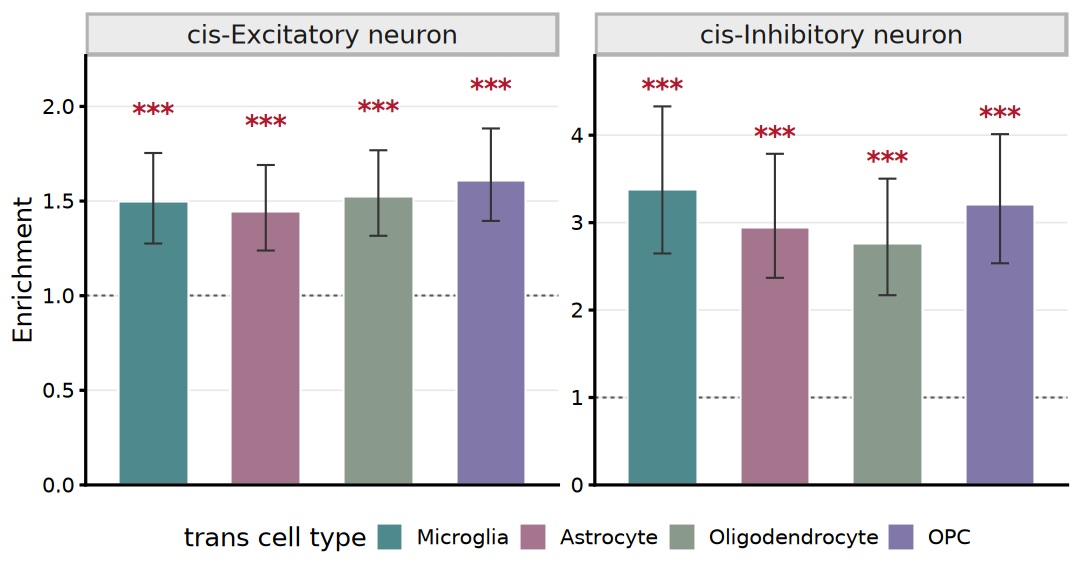

In [2]:
glia_cols <- c("Microglia" = "#4E8A8D", "Astrocyte" = "#A5748D",
               "Oligodendrocyte" = "#89998B", "OPC" = "#8177A8")
ymax <- max(res$bound_high) * 1.18
res$sig_y <- res$bound_high + 0.05 * max(res$bound_high)

p <- ggplot(res, aes(x = trans_glia, y = enrichment, fill = trans_glia)) +
  geom_hline(yintercept = 1, linetype = "dashed", colour = "grey35", linewidth = 0.45) +
  geom_col(width = 0.62, colour = "white", linewidth = 0.45) +
  geom_errorbar(aes(ymin = bound_low, ymax = bound_high), width = 0.16,
                linewidth = 0.45, colour = "grey20") +
  geom_text(aes(y = sig_y, label = sig), colour = "#B2182B", fontface = "bold", size = 5.5) +
  facet_wrap(~ cis_neuron, nrow = 1, scales = "free_y",
             labeller = labeller(cis_neuron = function(x) paste0("cis-", x))) +
  scale_fill_manual(values = glia_cols, name = "trans cell type") +
  scale_y_continuous(limits = c(0, NA), expand = expansion(mult = c(0, 0.08))) +
  labs(x = NULL, y = "Enrichment") +
  theme_classic(base_size = 15) +
  theme(strip.background = element_rect(fill = "grey92", colour = "grey70"),
        strip.text = element_text(size = 15),
        axis.text.x = element_blank(), axis.ticks.x = element_blank(),
        panel.grid.major.y = element_line(colour = "grey91", linewidth = 0.35),
        legend.position = "bottom")

options(repr.plot.width = 9, repr.plot.height = 4.8)
p